# **Mental** **Health** **Prediction**

   



# **1. Problem**

Mental health is an important aspect of well-being, and stress can affect individuals’ daily lives. Lifestyle habits such as sleep, exercise, diet, screen time, and social interaction may be related to different stress levels. Understanding these relationships can help reveal patterns associated with stress.

The problem addressed in this project is to analyze the relationship between lifestyle habits and stress levels and explore patterns in individuals’ daily habits. Using the Mental Health and Lifestyle Habits (2019–2024) dataset, the project aims to investigate whether lifestyle-related attributes can help predict stress levels.

This problem is important because identifying patterns related to stress can provide useful insights into mental well-being and improve our understanding of how lifestyle characteristics may be associated with different stress levels.

# **2. Data Mining Task**

This project addresses the mental health prediction problem using two data mining tasks: classification and clustering.

**Classification:** The classification task aims to predict an individual’s Stress Level based on lifestyle and demographic attributes, such as sleep hours, exercise level, diet type, screen time, and social interaction. The target attribute is Stress Level, which has three classes: Low, Moderate, and High. A Decision Tree classifier is used to perform this task.

**Clustering:** The clustering task aims to group individuals with similar lifestyle and mental health characteristics without using predefined class labels. K-means clustering is applied to identify groups of individuals who share similar patterns in their daily habits and well-being.

Together, these tasks help explore the relationship between lifestyle habits and stress levels through prediction and pattern discovery.

# **3. Data**

##  Project Goal

The goal of this project is to analyze the relationship between lifestyle habits and stress levels. The project aims to explore patterns related to stress and apply data mining techniques, including classification and clustering.

##  Dataset Source

Dataset Name: Mental Health and Lifestyle Habits (2019–2024)

Source: Kaggle

Dataset Link:
https://www.kaggle.com/datasets/atharvasoundankar/mental-health-and-lifestyle-habits-2019-2024

## Dataset Description

The dataset contains information related to lifestyle habits and mental well-being. It includes demographic and lifestyle-related attributes that can be used to explore their relationship with stress levels.



In [60]:
import pandas as pd

In [61]:
df = pd.read_csv("Raw_dataset.csv")

**Number** **and** **Data** **Types** **Of** **Attributes**

 The dataset consists of 12 attributes representing the mental health status and lifestyle habits of individuals.

The attributes and their corresponding data types are as follows:



In [62]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 12 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Country                      3000 non-null   object 
 1   Age                          3000 non-null   int64  
 2   Gender                       3000 non-null   object 
 3   Exercise Level               3000 non-null   object 
 4   Diet Type                    3000 non-null   object 
 5   Sleep Hours                  3000 non-null   float64
 6   Stress Level                 3000 non-null   object 
 7   Mental Health Condition      2405 non-null   object 
 8   Work Hours per Week          3000 non-null   int64  
 9   Screen Time per Day (Hours)  3000 non-null   float64
 10  Social Interaction Score     3000 non-null   float64
 11  Happiness Score              3000 non-null   float64
dtypes: float64(4), int64(2), object(6)
memory usage: 281.4+ KB


 **Number** **of** **Instances**

The dataset includes 3,000 instances, with each row representing survey data collected from an individual about their daily habits and psychological well-being.

In [63]:
print(f"Number of objects (instances/records): {df.shape[0]}")

Number of objects (instances/records): 3000


 **Class** **Attribute**


In [64]:

class_attribute = 'Stress Level'

print(f"Class Attribute: '{class_attribute}'")
print("\nUnique Class Values and Counts per Label:")
print(df[class_attribute].value_counts())

Class Attribute: 'Stress Level'

Unique Class Values and Counts per Label:
Stress Level
Low         1008
High        1002
Moderate     990
Name: count, dtype: int64


In [65]:
print(df["Stress Level"].unique())

['Low' 'High' 'Moderate']


The Stress Level attribute is divided into three categories (Low, Moderate, and High), representing the level of stress experienced by each participant. This attribute serves as the target variable for classification models.

 **Sample** **Of** **The** **Raw** **Data**

In [66]:

df.head()

,Country,Age,Gender,Exercise Level,Diet Type,Sleep Hours,Stress Level,Mental Health Condition,Work Hours per Week,Screen Time per Day (Hours),Social Interaction Score,Happiness Score
0,Brazil,48,Male,Low,Vegetarian,6.3,Low,NaN,21,4.0,7.8,6.5
1,Australia,31,Male,Moderate,Vegan,4.9,Low,PTSD,48,5.2,8.2,6.8
2,Japan,37,Female,Low,Vegetarian,7.2,High,NaN,43,4.7,9.6,9.7
3,Brazil,35,Male,Low,Vegan,7.2,Low,Depression,43,2.2,8.2,6.6
4,Germany,46,Male,Low,Balanced,7.3,Low,Anxiety,35,3.6,4.7,4.4


##  Data Understanding

In this section, we examine the structure and characteristics of the raw dataset before applying any preprocessing techniques.

In [67]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np



In [68]:
df = pd.read_csv("Raw_dataset.csv")

In [69]:

display(df.head())
df.shape
df.columns
df.info()

,Country,Age,Gender,Exercise Level,Diet Type,Sleep Hours,Stress Level,Mental Health Condition,Work Hours per Week,Screen Time per Day (Hours),Social Interaction Score,Happiness Score
0,Brazil,48,Male,Low,Vegetarian,6.3,Low,NaN,21,4.0,7.8,6.5
1,Australia,31,Male,Moderate,Vegan,4.9,Low,PTSD,48,5.2,8.2,6.8
2,Japan,37,Female,Low,Vegetarian,7.2,High,NaN,43,4.7,9.6,9.7
3,Brazil,35,Male,Low,Vegan,7.2,Low,Depression,43,2.2,8.2,6.6
4,Germany,46,Male,Low,Balanced,7.3,Low,Anxiety,35,3.6,4.7,4.4


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 12 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Country                      3000 non-null   object 
 1   Age                          3000 non-null   int64  
 2   Gender                       3000 non-null   object 
 3   Exercise Level               3000 non-null   object 
 4   Diet Type                    3000 non-null   object 
 5   Sleep Hours                  3000 non-null   float64
 6   Stress Level                 3000 non-null   object 
 7   Mental Health Condition      2405 non-null   object 
 8   Work Hours per Week          3000 non-null   int64  
 9   Screen Time per Day (Hours)  3000 non-null   float64
 10  Social Interaction Score     3000 non-null   float64
 11  Happiness Score              3000 non-null   float64
dtypes: float64(4), int64(2), object(6)
memory usage: 281.4+ KB



 The dataset consists of 3000 rows and 12 columns, featuring a combination of numerical and categorical attributes. Categorical attributes include Country, Gender, Exercise Level, Diet Type, Stress Level, and Mental Health Condition, while numerical attributes comprise Age, Sleep Hours, Work Hours per Week, Screen Time per Day, Social Interaction Score, and Happiness Score. Most columns contain complete data with 3000 non-null entries, except for "Mental Health Condition", which has 2405 non-null values, indicating 595 missing values. Consequently, data preprocessing will be necessary to handle these missing entries prior to building machine learning models.



## Statistical Summary (Five Number Summary)

In [70]:
df.describe()

,Age,Sleep Hours,Work Hours per Week,Screen Time per Day (Hours),Social Interaction Score,Happiness Score
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,41.229667,6.475933,39.466333,5.089833,5.470200,5.395067
std,13.428416,1.499866,11.451459,1.747231,2.563532,2.557601
min,18.000000,1.400000,20.000000,2.000000,1.000000,1.000000
25%,30.000000,5.500000,30.000000,3.600000,3.300000,3.200000
50%,41.000000,6.500000,39.000000,5.100000,5.500000,5.400000
75%,53.000000,7.500000,50.000000,6.600000,7.600000,7.500000
max,64.000000,11.300000,59.000000,8.000000,10.000000,10.000000



The statistical summary provides descriptive statistics for the dataset. The average age is about 41 years (ranging from 18 to 64), average sleep is 6.48 hours (1.4 to 11.3), average work hours is 39.47 per week (20 to 59), and average daily screen time is 5.09 hours (2 to 8). Additionally, Social Interaction and Happiness scores average around 5.47 and 5.39, respectively, with ranges from 1 to 10. Overall, the numerical attributes show a reasonable spread. Potential outliers are examined further using the IQR method and boxplots in the following section.



In [71]:
for col in df.select_dtypes(include=['int64', 'float64']).columns:
    print("Five-number summary for", col)
    print(df[col].describe()[['min', '25%', '50%', '75%', 'max']])
    print("-" * 30)
    print()


Five-number summary for Age
min    18.0
25%    30.0
50%    41.0
75%    53.0
max    64.0
Name: Age, dtype: float64
------------------------------

Five-number summary for Sleep Hours
min     1.4
25%     5.5
50%     6.5
75%     7.5
max    11.3
Name: Sleep Hours, dtype: float64
------------------------------

Five-number summary for Work Hours per Week
min    20.0
25%    30.0
50%    39.0
75%    50.0
max    59.0
Name: Work Hours per Week, dtype: float64
------------------------------

Five-number summary for Screen Time per Day (Hours)
min    2.0
25%    3.6
50%    5.1
75%    6.6
max    8.0
Name: Screen Time per Day (Hours), dtype: float64
------------------------------

Five-number summary for Social Interaction Score
min     1.0
25%     3.3
50%     5.5
75%     7.6
max    10.0
Name: Social Interaction Score, dtype: float64
------------------------------

Five-number summary for Happiness Score
min     1.0
25%     3.2
50%     5.4
75%     7.5
max    10.0
Name: Happiness Score, dtype: float64


 The five-number summary highlights the distribution of numerical attributes in the dataset. Age ranges from 18 to 64 (median 41), Sleep Hours from 1.4 to 11.3 (median 6.5), and Work Hours from 20 to 59 per week (median 39). Daily screen time ranges from 2 to 8 hours (median 5.1). Both Social Interaction and Happiness scores range from 1 to 10, with medians of 5.5 and 5.4, respectively. Overall, the numerical attributes show a reasonable spread, while potential outliers are examined further in the following section.


## Missing Values Analysis and Outlier Detection

##  Missing Values Analysis

Missing values are values that are not available or not recorded for some observations. Identifying missing values is an important step before applying data preprocessing techniques.

In [72]:
missing_analysis = pd.DataFrame({
    "Missing Values": df.isnull().sum()
})
display(missing_analysis)


,Missing Values
Country,0
Age,0
Gender,0
Exercise Level,0
Diet Type,0
Sleep Hours,0
Stress Level,0
Mental Health Condition,595
Work Hours per Week,0
Screen Time per Day (Hours),0


#### Missing Values Findings

Most attributes do not have missing values. However, 'Mental Health Condition' contains 595 missing values. Because this is a significant portion, imputation is required during the preprocessing stage to avoid losing records.

##  Outlier Detection

Outliers are observations that are unusually distant from the majority of the data. The Interquartile Range (IQR) method is used to identify potential outliers in the numerical attributes.

IQR = Q3 - Q1

Lower Bound = Q1 - 1.5 × IQR

Upper Bound = Q3 + 1.5 × IQR

Values below the lower bound or above the upper bound are considered potential outliers.

In [73]:
numeric_columns = df.select_dtypes(include=np.number).columns

outlier_summary = []

for column in numeric_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]

    outlier_summary.append({
        "Attribute": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Number of Outliers": len(outliers)
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary

,Attribute,Q1,Q3,IQR,Lower Bound,Upper Bound,Number of Outliers
0,Age,30.0,53.0,23.0,-4.50,87.50,0
1,Sleep Hours,5.5,7.5,2.0,2.50,10.50,16
2,Work Hours per Week,30.0,50.0,20.0,0.00,80.00,0
3,Screen Time per Day (Hours),3.6,6.6,3.0,-0.90,11.10,0
4,Social Interaction Score,3.3,7.6,4.3,-3.15,14.05,0
5,Happiness Score,3.2,7.5,4.3,-3.25,13.95,0


#### Outlier

The IQR method identified 16 potential outliers in "Sleep Hours". The other numerical attributes did not have any potential outliers using this method.

For "Sleep Hours", Q1 is 5.5 and Q3 is 7.5, giving an IQR of 2. The lower bound is 2.5 and the upper bound is 10.5. Therefore, values below 2.5 or above 10.5 were identified as potential outliers.


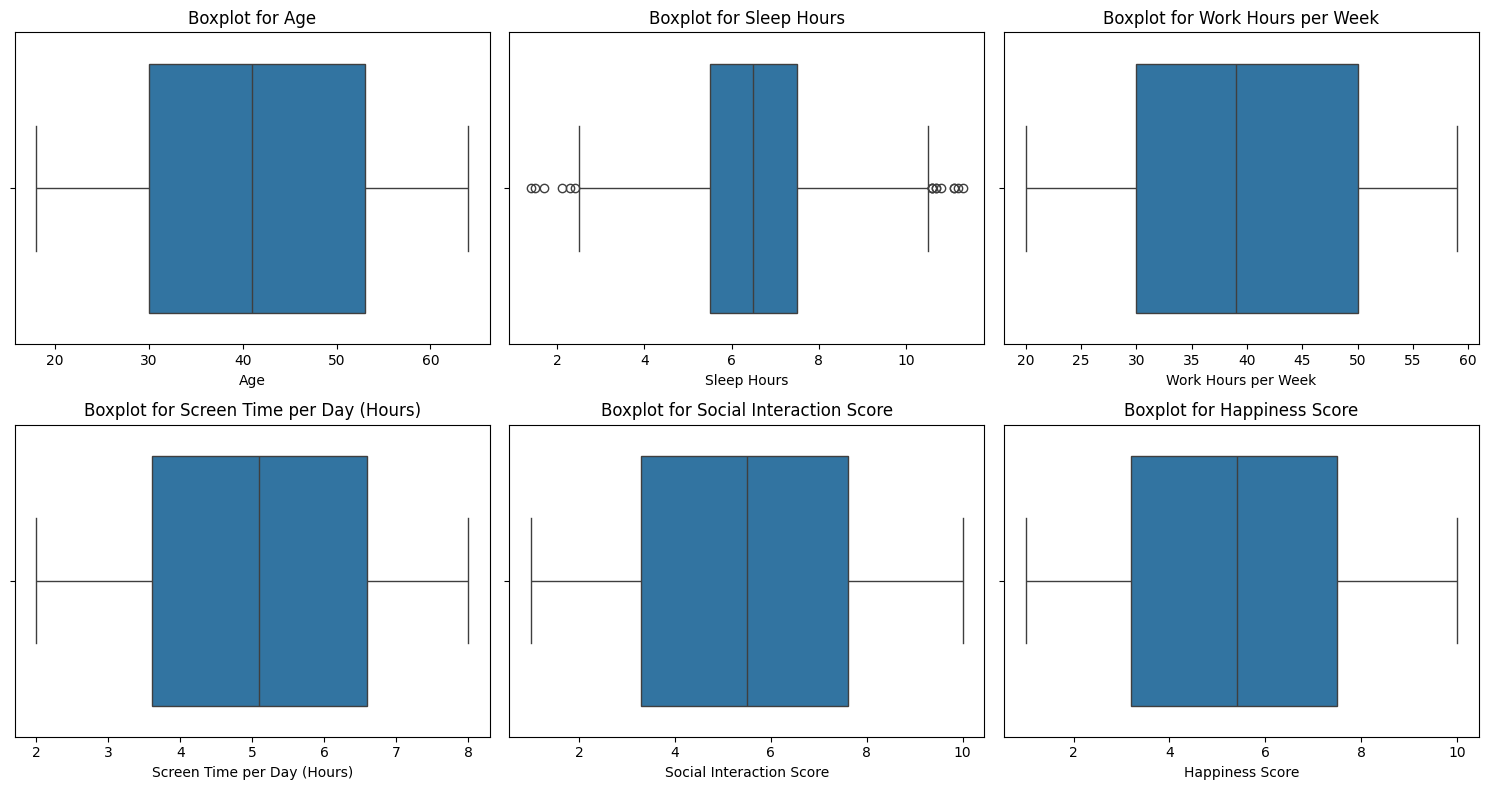

In [74]:
numeric_columns = [
    'Age',
    'Sleep Hours',
    'Work Hours per Week',
    'Screen Time per Day (Hours)',
    'Social Interaction Score',
    'Happiness Score'
]

plt.figure(figsize=(15, 8))

for i, column in enumerate(numeric_columns, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x=df[column])
    plt.title(f'Boxplot for {column}')

plt.tight_layout()
plt.show()

#### Boxplot

The boxplots show the distribution and spread of the numerical attributes. The "Sleep Hours" boxplot shows potential outlying values, which agrees with the IQR results. The other numerical attributes do not show potential outliers according to the IQR method. This indicates that Sleep Hours requires further preprocessing to handle the potential outliers before applying data mining techniques.

## Data Visualization and Class Label Distribution

## Class Label Distribution
The class label in this dataset is "Stress Level", which consists of three classes: Low, Moderate, and High. The following bar plot shows the distribution of these classes in the dataset.

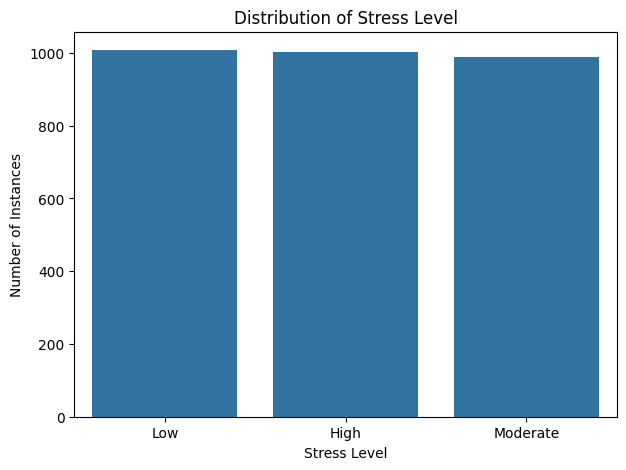

In [75]:
stress_counts = df['Stress Level'].value_counts()

plt.figure(figsize=(7, 5))
sns.barplot(x=stress_counts.index, y=stress_counts.values)

plt.title('Distribution of Stress Level')
plt.xlabel('Stress Level')
plt.ylabel('Number of Instances')
plt.show()

Class Label Distribution Findings

The bar plot shows that the three Stress Level classes are nearly balanced. Low has 1008 instances, High has 1002 instances, and Moderate has 990 instances. This indicates that class imbalance is not a major issue that needs to be addressed during preprocessing.

##  Variable Distribution

A histogram is used to examine the distribution of Sleep Hours, which is one of the numerical attributes in the dataset.

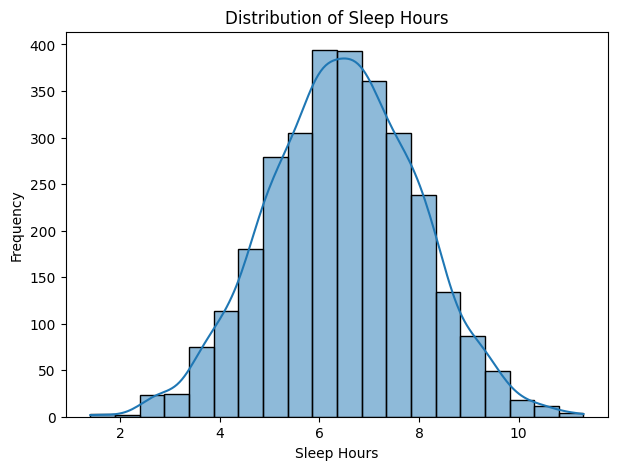

In [76]:
plt.figure(figsize=(7, 5))
sns.histplot(df['Sleep Hours'], bins=20, kde=True)

plt.title('Distribution of Sleep Hours')
plt.xlabel('Sleep Hours')
plt.ylabel('Frequency')
plt.show()

Histogram Findings

The histogram shows that Sleep Hours are approximately normally distributed, with most observations concentrated around 6 to 7 hours. Only a small number of observations appear at the lower and upper ends of the distribution. This supports the previous outlier analysis, which identified a small number of potential outliers in Sleep Hours. Therefore, Sleep Hours requires further preprocessing to handle the potential outliers.

##  Relationship Between Numerical Attributes

A scatter plot is used to examine the relationship between Sleep Hours and Happiness Score across the different Stress Level classes.

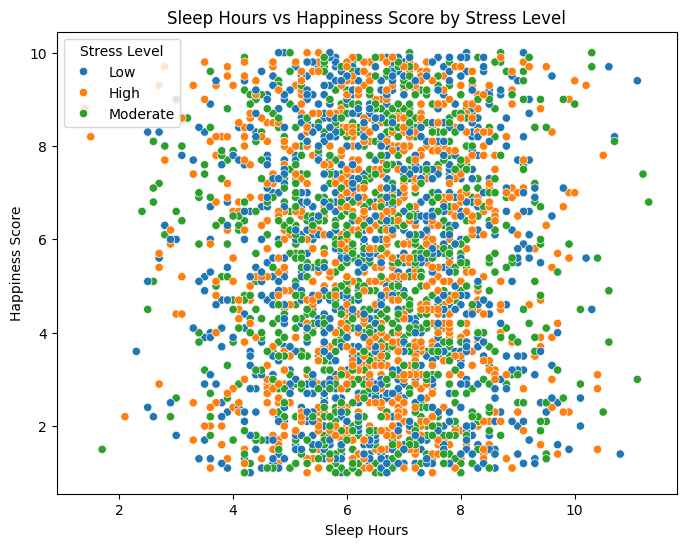

In [77]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='Sleep Hours',
    y='Happiness Score',
    hue='Stress Level'
)

plt.title('Sleep Hours vs Happiness Score by Stress Level')
plt.xlabel('Sleep Hours')
plt.ylabel('Happiness Score')
plt.show()

Scatter Plot Findings

The scatter plot shows substantial overlap among the Low, Moderate, and High Stress Level classes. There is no clear separation between the classes based on Sleep Hours and Happiness Score, and no strong relationship between these two attributes is visually apparent. This suggests that these two attributes alone may not be sufficient to distinguish between the Stress Level classes. The plot does not indicate a specific preprocessing issue for these two attributes.

# **4. Data Preprocessing**

Several preprocessing techniques were applied to prepare the dataset (based on Phase 2), while keeping a copy of the raw data unchanged:

**1. Handling Missing Values:** Missing values in the Mental Health Condition attribute were filled using the mode (most frequent value), since it is a categorical attribute.

**2. Outlier Detection and Treatment:** Outliers in numeric attributes (e.g., Sleep Hours) were detected using the IQR method (Q1, Q3, and 1.5×IQR bounds) and treated to reduce noise.

**3. Data Normalization:** Numeric attributes were scaled to a common range [0, 1] using Min-Max Scaling (sklearn.preprocessing.MinMaxScaler), so that attributes with larger ranges do not dominate the analysis.

The processed data was saved separately as Preprocessed_dataset.csv, and this preprocessed version is the one used in the classification and clustering tasks.


## Data Preprocessing





Data preprocessing is applied to prepare the dataset for data mining techniques. the identified missing values and potential outliers are treated while preserving the original dataset. A separate copy of the dataset is used for preprocessing.

##  Creating a Copy of the Dataset

A copy of the original dataset was created before applying any preprocessing techniques. This ensures that the original dataset remains unchanged.

In [78]:
processed_df = df.copy()

print("Original dataset shape:", df.shape)
print("Processed dataset shape:", processed_df.shape)

Original dataset shape: (3000, 12)
Processed dataset shape: (3000, 12)


## Handling Missing Values

The missing value analysis showed that the "Mental Health Condition" attribute contains 595 missing values.

Since "Mental Health Condition" is a categorical attribute, the mode was used to replace the missing values. The mode is "Anxiety", which is the most frequent category in the dataset.

In [79]:
mode_value = processed_df["Mental Health Condition"].mode()[0]

processed_df["Mental Health Condition"] = processed_df[
    "Mental Health Condition"
].fillna(mode_value)

print("Mode used:", mode_value)
print("Missing values after treatment:",
      processed_df["Mental Health Condition"].isnull().sum())

Mode used: Anxiety
Missing values after treatment: 0


### Missing Values Findings

The 595 missing values in "Mental Health Condition" were replaced using mode imputation. The mode was "Anxiety". After the treatment, no missing values remained in this attribute, and all 3,000 records were retained.

## Outlier Detection and Treatment

During the Data Analysis phase, the IQR method identified potential outliers in the "Sleep Hours" attribute.

The IQR method was used to calculate the lower and upper bounds. Instead of removing the outlier records, IQR capping was applied to reduce the effect of extreme values while preserving all observations.

In [80]:
Q1 = processed_df["Sleep Hours"].quantile(0.25)
Q3 = processed_df["Sleep Hours"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 5.5
Q3: 7.5
IQR: 2.0
Lower Bound: 2.5
Upper Bound: 10.5


In [81]:
outliers_before = (
    (processed_df["Sleep Hours"] < lower_bound) |
    (processed_df["Sleep Hours"] > upper_bound)
).sum()

print("Potential outliers before treatment:", outliers_before)

processed_df["Sleep Hours"] = processed_df["Sleep Hours"].clip(
    lower=lower_bound,
    upper=upper_bound
)

print("Minimum after treatment:",
      processed_df["Sleep Hours"].min())

print("Maximum after treatment:",
      processed_df["Sleep Hours"].max())

Potential outliers before treatment: 16
Minimum after treatment: 2.5
Maximum after treatment: 10.5


### Boxplot After Outlier Treatment

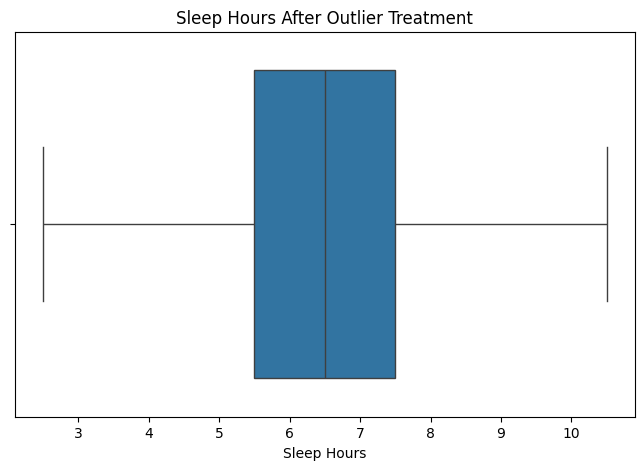

In [82]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=processed_df["Sleep Hours"])

plt.title("Sleep Hours After Outlier Treatment")
plt.xlabel("Sleep Hours")

plt.show()

### Outlier Treatment Findings

The IQR method identified 16 potential outliers in "Sleep Hours". The calculated lower and upper bounds were 2.5 and 10.5 hours, respectively.

IQR capping was applied to "Sleep Hours". Values below 2.5 were replaced with 2.5, while values above 10.5 were replaced with 10.5. This treatment preserved all 3,000 records while reducing the effect of extreme values.

## Data Normalization


Data normalization is a preprocessing technique used to scale numerical attributes to a common range. It helps make the values comparable and prevents attributes with larger numerical ranges from having a greater influence on the analysis.

In [83]:
from sklearn.preprocessing import MinMaxScaler
columns_to_normalize=['Age',
                      'Sleep Hours',
                      'Work Hours per Week',
                      'Screen Time per Day (Hours)',
                      'Social Interaction Score',
                      'Happiness Score']
scaler=MinMaxScaler()

processed_df[columns_to_normalize]=scaler.fit_transform(processed_df[columns_to_normalize])
processed_df[columns_to_normalize].head()

,Age,Sleep Hours,Work Hours per Week,Screen Time per Day (Hours),Social Interaction Score,Happiness Score
0,0.652174,0.4750,0.025641,0.333333,0.755556,0.611111
1,0.282609,0.3000,0.717949,0.533333,0.800000,0.644444
2,0.413043,0.5875,0.589744,0.450000,0.955556,0.966667
3,0.369565,0.5875,0.589744,0.033333,0.800000,0.622222
4,0.608696,0.6000,0.384615,0.266667,0.411111,0.377778


The Min-Max Scaling technique transformed all selected numerical attributes into a common range between 0 and 1. The normalized values show that the original differences in measurement scales were reduced. For example, the Age values were transformed into values between 0 and 1, and the same transformation was applied to Sleep Hours, Work Hours per Week, Screen Time per Day, Social Interaction Score, and Happiness Score. This makes the numerical attributes comparable and reduces the influence of attributes with larger original scales.

## Preprocessed Dataset Snapshot

The following table shows a sample of the dataset after applying the preprocessing techniques.

In [84]:
display(processed_df.head())

,Country,Age,Gender,Exercise Level,Diet Type,Sleep Hours,Stress Level,Mental Health Condition,Work Hours per Week,Screen Time per Day (Hours),Social Interaction Score,Happiness Score
0,Brazil,0.652174,Male,Low,Vegetarian,0.4750,Low,Anxiety,0.025641,0.333333,0.755556,0.611111
1,Australia,0.282609,Male,Moderate,Vegan,0.3000,Low,PTSD,0.717949,0.533333,0.800000,0.644444
2,Japan,0.413043,Female,Low,Vegetarian,0.5875,High,Anxiety,0.589744,0.450000,0.955556,0.966667
3,Brazil,0.369565,Male,Low,Vegan,0.5875,Low,Depression,0.589744,0.033333,0.800000,0.622222
4,Germany,0.608696,Male,Low,Balanced,0.6000,Low,Anxiety,0.384615,0.266667,0.411111,0.377778


## Saving The Preprocessed Dataset

The processed dataset was saved as a separate CSV file named Preprocessed_dataset.csv.

In [85]:
processed_df.to_csv("Preprocessed_dataset.csv", index=False)

The file contains the data after applying the preprocessing techniques.

# **5. Data Mining Technique**

Two data mining techniques are applied to the preprocessed dataset:

**1. Classification — Decision Tree**
A Decision Tree classifier is used to predict the class label (Stress Level: Low, Moderate, High) using two attribute selection measures — Information Gain (Entropy) and the Gini index — evaluated on three train/test partitions (90/10, 80/20, 70/30). Python package: sklearn.tree.DecisionTreeClassifier, evaluated with sklearn.metrics (accuracy and confusion matrix).

**2. Clustering — K-Means**
K-Means groups records with similar lifestyle profiles (unsupervised). The Elbow method (WCSS) and the Silhouette coefficient are computed for K from 2 to 10 to justify the choice of K, then three values (K = 3, 4, 5) are compared in detail and the optimal K is selected using the majority rule.Categorical attributes are converted using one-hot encoding (sklearn.preprocessing.OneHotEncoder) and clusters are visualized with PCA. Python packages: sklearn.cluster.KMeans, sklearn.metrics.silhouette_score, sklearn.decomposition.PCA.


# **6. Evaluation and Comparison**




## 6.1  For Classification


In this section, we evaluate and compare the performance of the Decision Tree classification models (Gini Index vs. Entropy / Information Gain) across all three data partitions (90/10, 80/20, 70/30). Confusion matrices, evaluation metrics (Accuracy, Precision, Recall, F1-Score), and Feature Importance analysis are presented below.

In [86]:
import pandas as pd

df = pd.read_csv("Preprocessed_dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())
print(df.dtypes)

Dataset shape: (3000, 12)


,Country,Age,Gender,Exercise Level,Diet Type,Sleep Hours,Stress Level,Mental Health Condition,Work Hours per Week,Screen Time per Day (Hours),Social Interaction Score,Happiness Score
0,Brazil,0.652174,Male,Low,Vegetarian,0.4750,Low,Anxiety,0.025641,0.333333,0.755556,0.611111
1,Australia,0.282609,Male,Moderate,Vegan,0.3000,Low,PTSD,0.717949,0.533333,0.800000,0.644444
2,Japan,0.413043,Female,Low,Vegetarian,0.5875,High,Anxiety,0.589744,0.450000,0.955556,0.966667
3,Brazil,0.369565,Male,Low,Vegan,0.5875,Low,Depression,0.589744,0.033333,0.800000,0.622222
4,Germany,0.608696,Male,Low,Balanced,0.6000,Low,Anxiety,0.384615,0.266667,0.411111,0.377778


Country                         object
Age                            float64
Gender                          object
Exercise Level                  object
Diet Type                       object
Sleep Hours                    float64
Stress Level                    object
Mental Health Condition         object
Work Hours per Week            float64
Screen Time per Day (Hours)    float64
Social Interaction Score       float64
Happiness Score                float64
dtype: object


In [87]:
# Separate features and target
X = df.drop(columns=['Stress Level'])
y = df['Stress Level']

# Convert categorical features to numeric values
X = pd.get_dummies(X, dtype=int)

print("Features shape:", X.shape)
print("Target classes:", y.unique())
print("Missing values:", X.isnull().sum().sum())

Features shape: (3000, 28)
Target classes: ['Low' 'High' 'Moderate']
Missing values: 0


In [88]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Split the dataset: 90% training and 10% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42, stratify=y
)

# Train Decision Tree using Gini Index
gini_model = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

gini_model.fit(X_train, y_train)

# Predict and calculate accuracy
y_pred = gini_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print("Training size:", len(X_train))
print("Testing size:", len(X_test))
print("Gini Accuracy (90/10):", round(accuracy * 100, 2), "%")

Training size: 2700
Testing size: 300
Gini Accuracy (90/10): 34.0 %


In [89]:
# Split the dataset: 80% training and 20% testing
X_train_80, X_test_20, y_train_80, y_test_20 = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train Decision Tree using Gini Index
gini_model_80 = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

gini_model_80.fit(X_train_80, y_train_80)

# Predict and calculate accuracy
y_pred_20 = gini_model_80.predict(X_test_20)
accuracy_80 = accuracy_score(y_test_20, y_pred_20)

print("Training size:", len(X_train_80))
print("Testing size:", len(X_test_20))
print("Gini Accuracy (80/20):", round(accuracy_80 * 100, 2), "%")

Training size: 2400
Testing size: 600
Gini Accuracy (80/20): 37.17 %


In [90]:
# Split the dataset: 70% training and 30% testing
X_train_70, X_test_30, y_train_70, y_test_30 = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Train Decision Tree using Gini Index
gini_model_70 = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

gini_model_70.fit(X_train_70, y_train_70)

# Predict and calculate accuracy
y_pred_30 = gini_model_70.predict(X_test_30)
accuracy_70 = accuracy_score(y_test_30, y_pred_30)

print("Training size:", len(X_train_70))
print("Testing size:", len(X_test_30))
print("Gini Accuracy (70/30):", round(accuracy_70 * 100, 2), "%")

Training size: 2100
Testing size: 900
Gini Accuracy (70/30): 31.89 %


In [91]:
# Compare Gini accuracy across the three partitions
gini_results = pd.DataFrame({
    'Training / Testing': ['90/10', '80/20', '70/30'],
    'Accuracy (%)': [
        round(accuracy * 100, 2),
        round(accuracy_80 * 100, 2),
        round(accuracy_70 * 100, 2)
    ]
})

display(gini_results)

,Training / Testing,Accuracy (%)
0,90/10,34.00
1,80/20,37.17
2,70/30,31.89


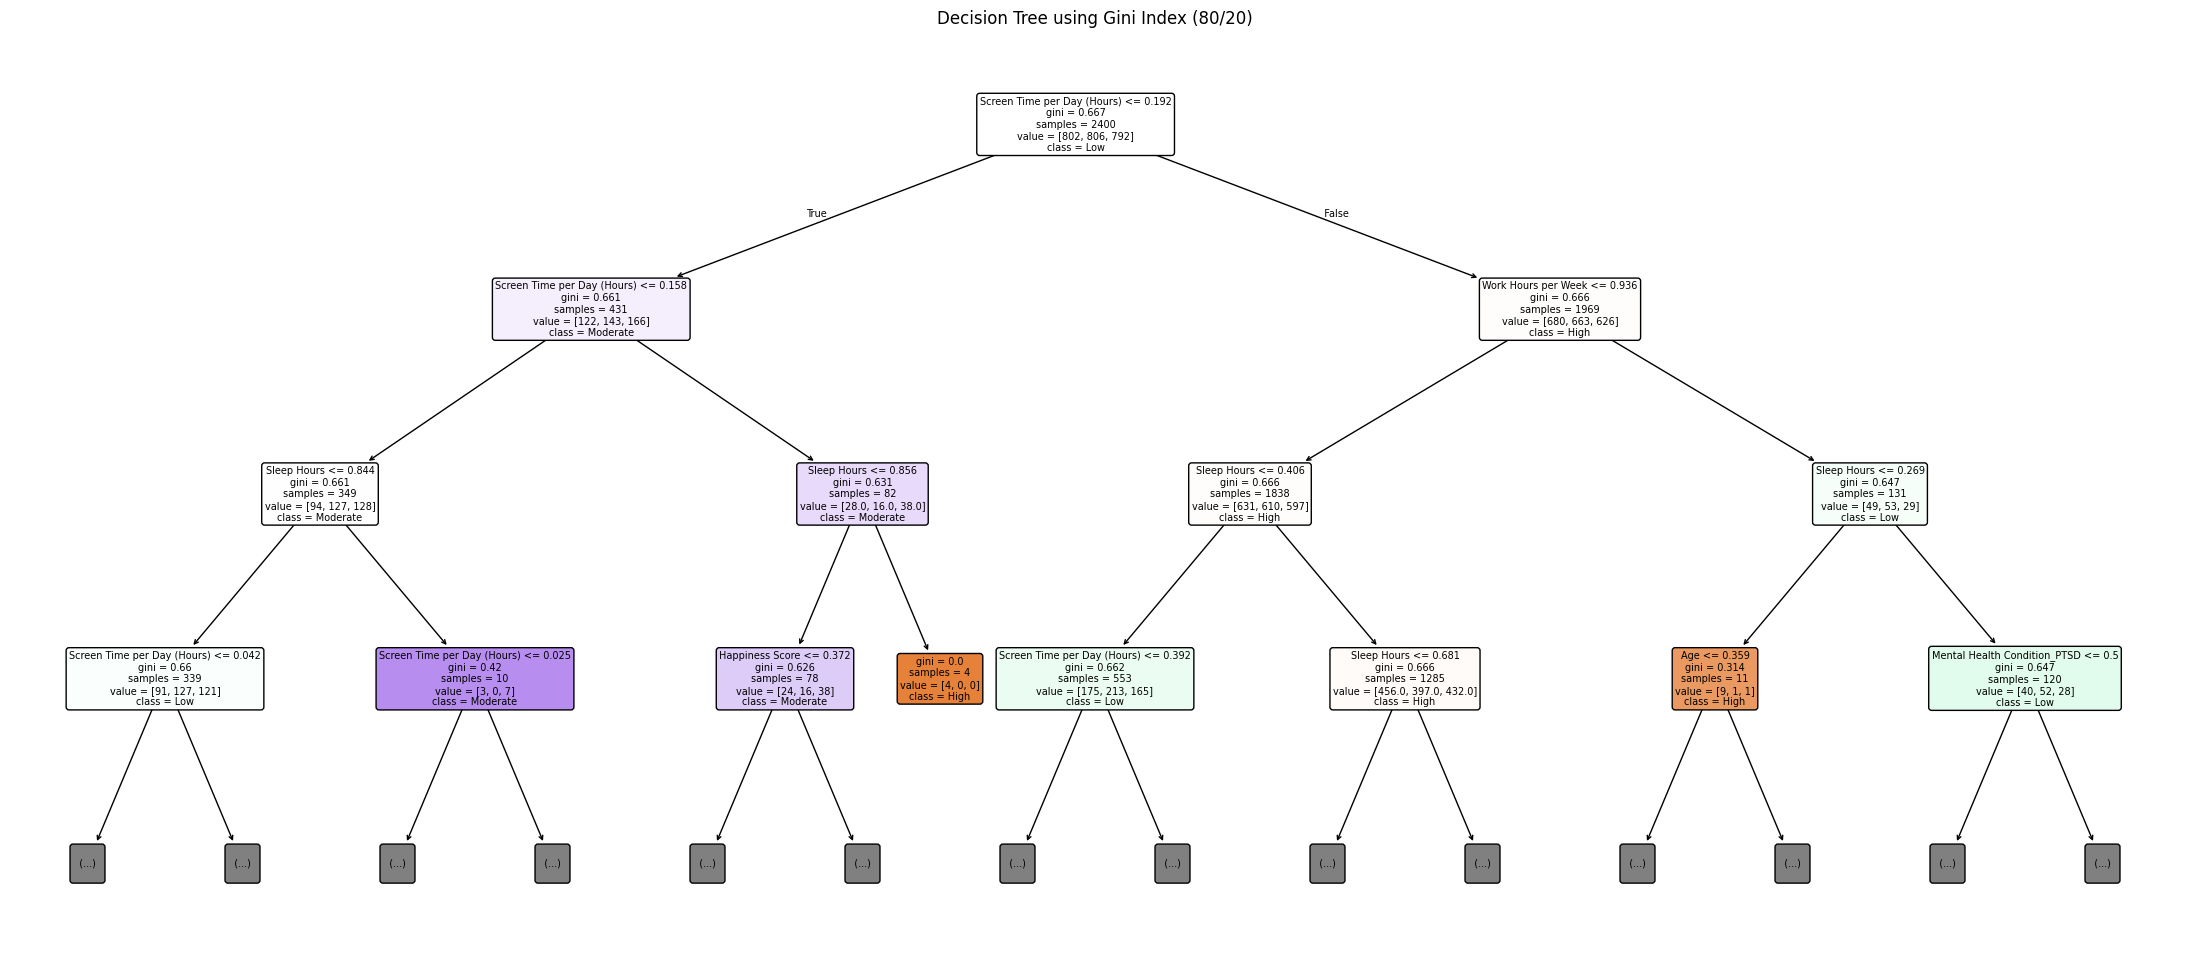

In [92]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Visualize the Gini Decision Tree (80/20)
plt.figure(figsize=(28, 12))

plot_tree(
    gini_model_80,
    feature_names=X.columns,
    class_names=gini_model_80.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=7
)

plt.title("Decision Tree using Gini Index (80/20)")
plt.show()

## Gini Index Classification Findings

The Decision Tree classifier was applied using the Gini index to predict Stress Level (Low, Moderate, and High). Three training/testing partitions were tested: 90/10, 80/20, and 70/30.

The accuracy results were 34.00%, 37.17%, and 31.89%, respectively. The 80/20 partition achieved the highest accuracy among the three experiments.

The decision tree visualization shows that Screen Time per Day (Hours) was selected for the first split, followed by attributes such as Sleep Hours and Work Hours per Week.

Overall, the classification accuracy was low across all three partitions, indicating that the Decision Tree model had difficulty distinguishing between the three Stress Level classes using the available features.

## Entropy / Information Gain Classification

In [93]:
#Split the dataset: 90% training and 10% testing

X_train_entropy, X_test_entropy, y_train_entropy, y_test_entropy= train_test_split(X,y,
test_size=0.1, random_state=42, stratify=y)

print("Training size: ", len(X_train_entropy))
print("Testing size: ", len(X_test_entropy))


Training size:  2700
Testing size:  300


In [94]:
#Tree Decision Tree using Entropy
entropy_model= DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

#Train the model
entropy_model.fit(X_train_entropy, y_train_entropy)

DecisionTreeClassifier(criterion='entropy', random_state=42)

In [95]:
#Predict using the trained model
y_pred_entropy=entropy_model.predict(X_test_entropy)

#calculate accuracy
accuracy_entropy= accuracy_score(y_test_entropy, y_pred_entropy)
print("Entropy Accuracy (90/10): ", round(accuracy_entropy*100, 2), "%")

Entropy Accuracy (90/10):  33.67 %


In [96]:
#Split the dataset: 80% training and 20% testing
X_train_entropy_80, X_test_entropy_80, y_train_entropy_80, y_test_entropy_80= train_test_split(X,y,
test_size=0.2, random_state=42, stratify=y)

#Creat Decision Tree Using Entropy
entropy_model_80= DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

#Train the model
entropy_model_80.fit(X_train_entropy_80, y_train_entropy_80)

#Predict
y_pred_entropy_80=entropy_model_80.predict(X_test_entropy_80)

#calculate accuracy
accuracy_entropy_80= accuracy_score(y_test_entropy_80, y_pred_entropy_80)

print("Training size: ", len(X_train_entropy_80))
print("Testing size: ", len(X_test_entropy_80))
print("Entropy Accuracy (80/20): ", round(accuracy_entropy_80*100, 2), "%")



Training size:  2400
Testing size:  600
Entropy Accuracy (80/20):  34.33 %


In [97]:
#Split the dataset: 70% training and 30% testing
X_train_entropy_70, X_test_entropy_70, y_train_entropy_70, y_test_entropy_70= train_test_split(X,y,
test_size=0.3, random_state=42, stratify=y)

#Creat Decision Tree Using Entropy
entropy_model_70= DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

#Train the model
entropy_model_70.fit(X_train_entropy_70, y_train_entropy_70)

#Predict
y_pred_entropy_70=entropy_model_70.predict(X_test_entropy_70)

#calculate accuracy
accuracy_entropy_70= accuracy_score(y_test_entropy_70, y_pred_entropy_70)

print("Training size: ", len(X_train_entropy_70))
print("Testing size: ", len(X_test_entropy_70))
print("Entropy Accuracy (70/30): ", round(accuracy_entropy_70*100, 2), "%")

Training size:  2100
Testing size:  900
Entropy Accuracy (70/30):  34.78 %


In [98]:
# Compare Entropy accuracy across the three partitions
entropy_results = pd.DataFrame({
    'Training / Testing': ['90/10', '80/20', '70/30'],
    'Accuracy (%)': [
        round(accuracy_entropy * 100, 2),
        round(accuracy_entropy_80 * 100, 2),
        round(accuracy_entropy_70 * 100, 2)
    ]
})

display(entropy_results)

,Training / Testing,Accuracy (%)
0,90/10,33.67
1,80/20,34.33
2,70/30,34.78


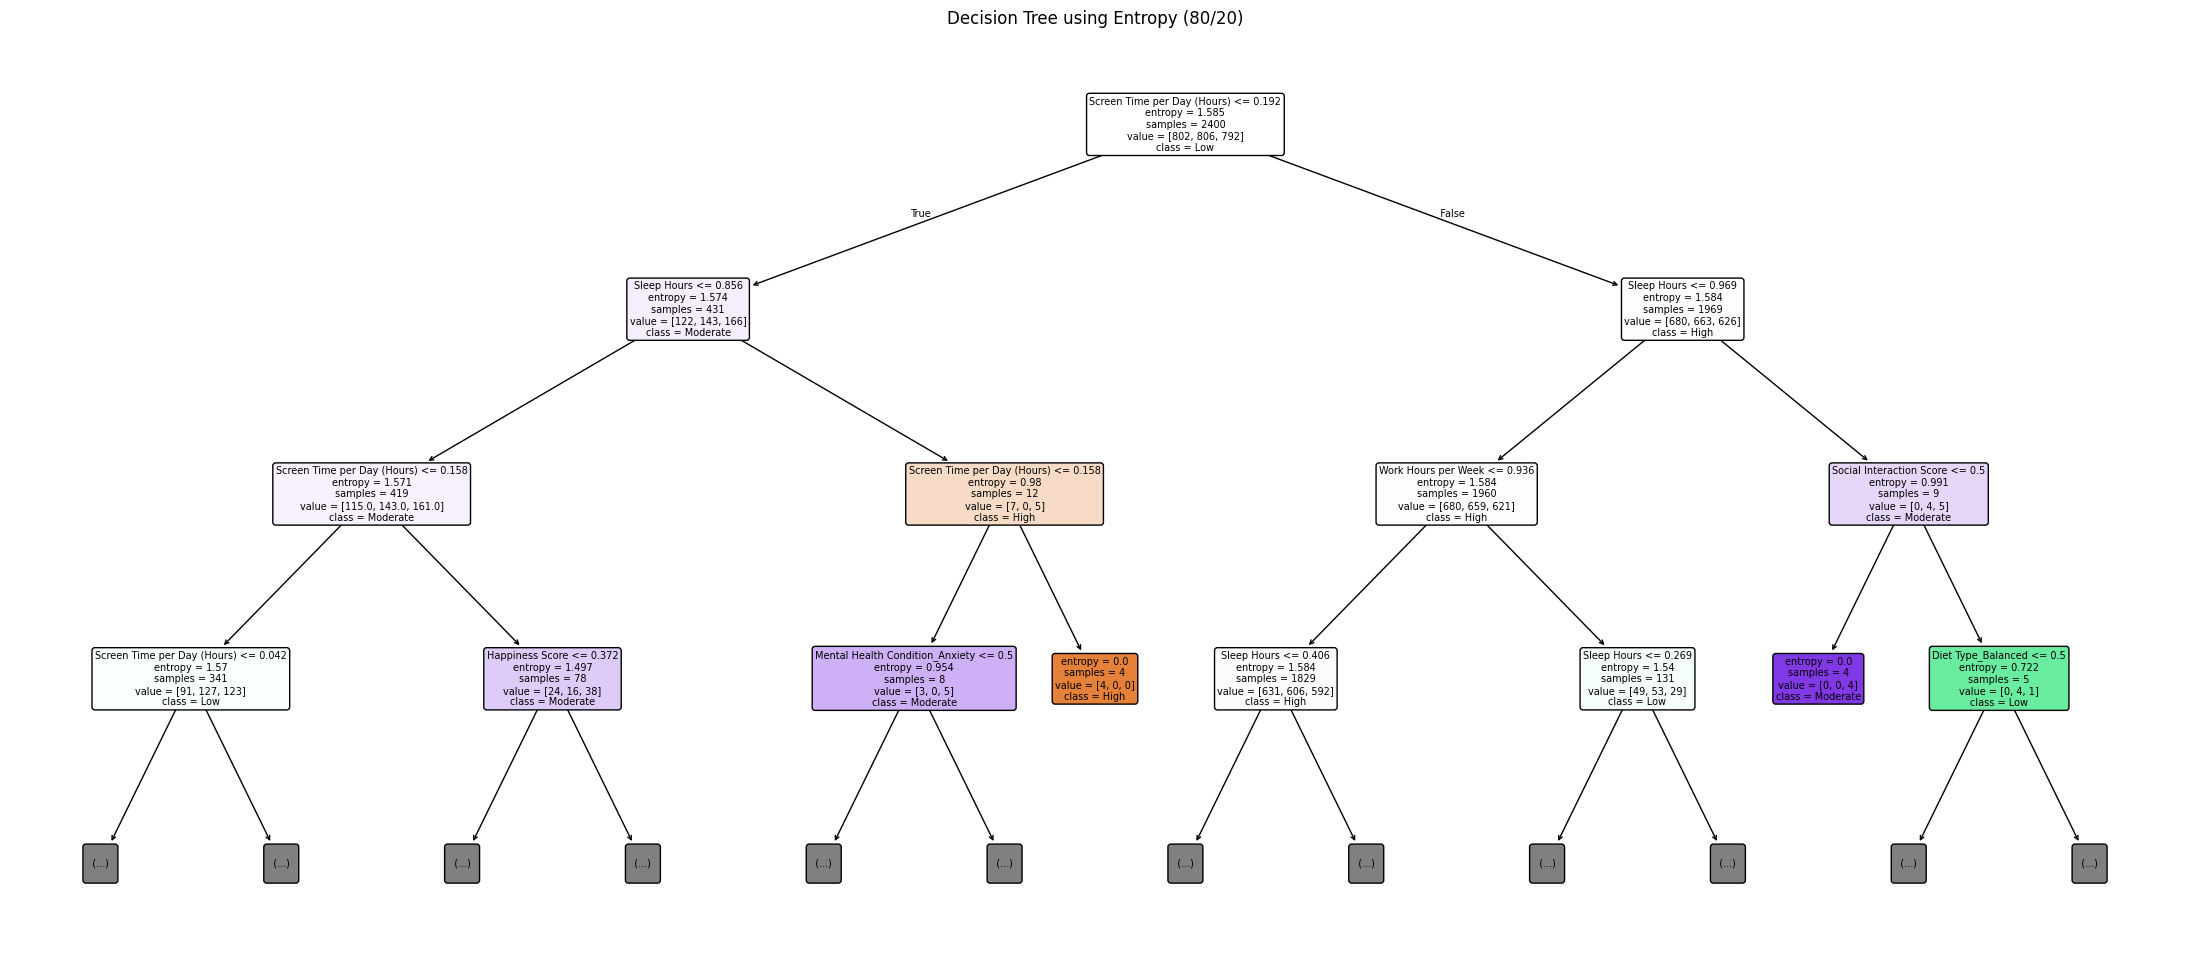

In [99]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Visualize the Entropy Decision Tree (80/20)
plt.figure(figsize=(28, 12))

plot_tree(
    entropy_model_80,
    feature_names=X.columns,
    class_names=entropy_model_80.classes_.astype(str),
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=7
)

plt.title("Decision Tree using Entropy (80/20)")
plt.show()

## Entropy / Information Gain Findings

The Decision Tree classifier using Entropy was evaluated using three different data partitions: 90/10, 80/20, and 70/30.

The accuracy results were 33.67%, 34.33%, and 34.78%, respectively. The 70/30 partition achieved the highest accuracy among the three experiments, while the 90/10 partition achieved the lowest accuracy.

The results indicate that the Entropy-based Decision Tree achieved relatively low accuracy across all three partitions, showing limited ability to distinguish between the three Stress Level classes using the available features.

The Decision Tree visualization for the 80/20 partition illustrates how the model uses different attributes to split the dataset and classify individuals into Stress Level categories.

Overall, the Entropy-based Decision Tree showed limited classification performance on this dataset, with the 70/30 partition producing the best accuracy among the tested partitions.

In [100]:
from sklearn.metrics import confusion_matrix, classification_report
import pandas as pd

# -------------------------------------------------------------
# 1. Gini Index Confusion Matrices & Classification Reports
# -------------------------------------------------------------
print("==================================================")
print("       GINI INDEX CLASSIFICATION EVALUATION       ")
print("==================================================")

print("\n--- Gini Index (90/10 Partition) ---")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\n--- Gini Index (80/20 Partition) ---")
print("Confusion Matrix:")
print(confusion_matrix(y_test_20, y_pred_20))
print("\nClassification Report:")
print(classification_report(y_test_20, y_pred_20))

print("\n--- Gini Index (70/30 Partition) ---")
print("Confusion Matrix:")
print(confusion_matrix(y_test_30, y_pred_30))
print("\nClassification Report:")
print(classification_report(y_test_30, y_pred_30))

# -------------------------------------------------------------
# 2. Entropy Confusion Matrices & Classification Reports
# -------------------------------------------------------------
print("\n==================================================")
print("         ENTROPY CLASSIFICATION EVALUATION        ")
print("==================================================")

print("\n--- Entropy (90/10 Partition) ---")
print("Confusion Matrix:")
print(confusion_matrix(y_test_entropy, y_pred_entropy))
print("\nClassification Report:")
print(classification_report(y_test_entropy, y_pred_entropy))

print("\n--- Entropy (80/20 Partition) ---")
print("Confusion Matrix:")
print(confusion_matrix(y_test_entropy_80, y_pred_entropy_80))
print("\nClassification Report:")
print(classification_report(y_test_entropy_80, y_pred_entropy_80))

print("\n--- Entropy (70/30 Partition) ---")
print("Confusion Matrix:")
print(confusion_matrix(y_test_entropy_70, y_pred_entropy_70))
print("\nClassification Report:")
print(classification_report(y_test_entropy_70, y_pred_entropy_70))

       GINI INDEX CLASSIFICATION EVALUATION       

--- Gini Index (90/10 Partition) ---
Confusion Matrix:
[[31 34 35]
 [27 42 32]
 [38 32 29]]

Classification Report:
              precision    recall  f1-score   support

        High       0.32      0.31      0.32       100
         Low       0.39      0.42      0.40       101
    Moderate       0.30      0.29      0.30        99

    accuracy                           0.34       300
   macro avg       0.34      0.34      0.34       300
weighted avg       0.34      0.34      0.34       300


--- Gini Index (80/20 Partition) ---
Confusion Matrix:
[[77 61 62]
 [62 66 74]
 [50 68 80]]

Classification Report:
              precision    recall  f1-score   support

        High       0.41      0.39      0.40       200
         Low       0.34      0.33      0.33       202
    Moderate       0.37      0.40      0.39       198

    accuracy                           0.37       600
   macro avg       0.37      0.37      0.37       600
weighted

In [101]:
# --- Required Accuracy Tables Matching Guidelines ---
# Gini Index Accuracy Table
gini_table = pd.DataFrame({
    '90% training set 10% testing set': [round(accuracy * 100, 2)],
    '80% training set 20% testing set': [round(accuracy_80 * 100, 2)],
    '70% training set 30% testing set': [round(accuracy_70 * 100, 2)]
}, index=['Accuracy (%)'])

print("Table 1: Gini Index Decision Tree Accuracy")
display(gini_table)

# Entropy / Information Gain Accuracy Table
entropy_table = pd.DataFrame({
    '90% training set 10% testing set': [round(accuracy_entropy * 100, 2)],
    '80% training set 20% testing set': [round(accuracy_entropy_80 * 100, 2)],
    '70% training set 30% testing set': [round(accuracy_entropy_70 * 100, 2)]
}, index=['Accuracy (%)'])

print("Table 2: Entropy Decision Tree Accuracy")
display(entropy_table)

Table 1: Gini Index Decision Tree Accuracy


,90% training set 10% testing set,80% training set 20% testing set,70% training set 30% testing set
Accuracy (%),34.0,37.17,31.89


Table 2: Entropy Decision Tree Accuracy


,90% training set 10% testing set,80% training set 20% testing set,70% training set 30% testing set
Accuracy (%),33.67,34.33,34.78


In [102]:
# Create a comprehensive summary table comparing Gini and Entropy across all partitions
classification_comparison = pd.DataFrame({
    'Attribute Selection Measure': ['Gini Index', 'Gini Index', 'Gini Index', 'Entropy (IG)', 'Entropy (IG)', 'Entropy (IG)'],
    'Training / Testing Split': ['90% / 10%', '80% / 20%', '70% / 30%', '90% / 10%', '80% / 20%', '70% / 30%'],
    'Accuracy (%)': [
        round(accuracy * 100, 2),
        round(accuracy_80 * 100, 2),
        round(accuracy_70 * 100, 2),
        round(accuracy_entropy * 100, 2),
        round(accuracy_entropy_80 * 100, 2),
        round(accuracy_entropy_70 * 100, 2)
    ]
})

print("Classification Performance Comparison Table:")
display(classification_comparison)

Classification Performance Comparison Table:


,Attribute Selection Measure,Training / Testing Split,Accuracy (%)
0,Gini Index,90% / 10%,34.00
1,Gini Index,80% / 20%,37.17
2,Gini Index,70% / 30%,31.89
3,Entropy (IG),90% / 10%,33.67
4,Entropy (IG),80% / 20%,34.33
5,Entropy (IG),70% / 30%,34.78


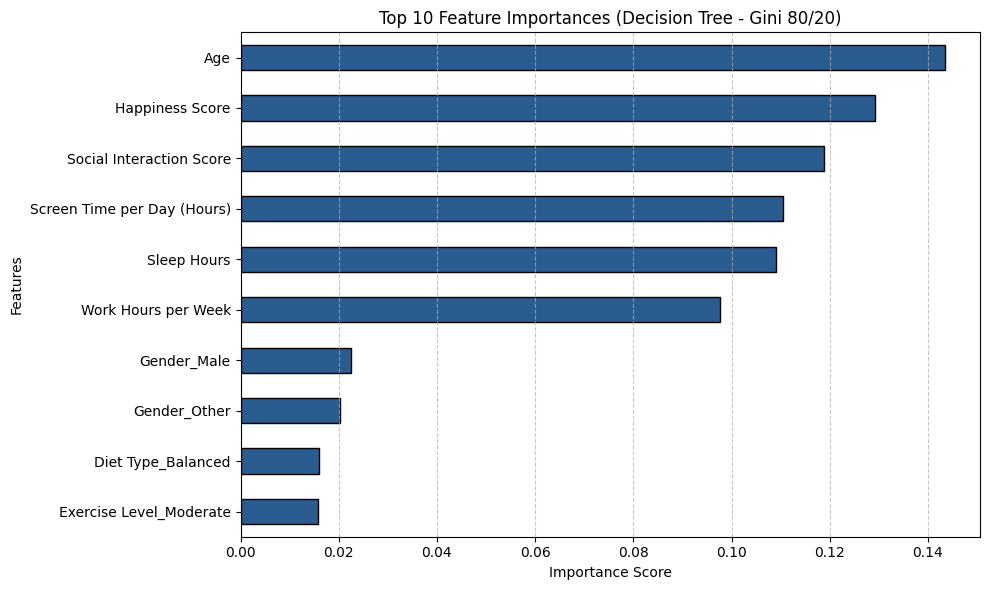

In [103]:
import matplotlib.pyplot as plt

# Extract feature importances from the overall best model (Gini Index 80/20)
importances = gini_model_80.feature_importances_
feature_names = X.columns

# Sort top features
feature_imp_df = pd.Series(importances, index=feature_names).sort_values(ascending=True)

# Plot top 10 important features
plt.figure(figsize=(10, 6))
feature_imp_df.tail(10).plot(kind='barh', color='#2b5c8f', edgecolor='black')
plt.title("Top 10 Feature Importances (Decision Tree - Gini 80/20)")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Classification Evaluation Findings & Comparison

The Decision Tree classification models were evaluated and compared using two attribute selection measures (**Gini Index** and **Entropy / Information Gain**) across three data partitioning ratios (**90/10**, **80/20**, and **70/30**).

#### Key Evaluation Insights:

**1. Partitioning Performance Comparison**

* **Gini Index:** The **80/20 partition** achieved the best accuracy (**37.17%**), followed by 90/10 (**34.00%**) and 70/30 (**31.89%**).
* **Entropy / Information Gain:** The **70/30 partition** achieved the best accuracy (**34.78%**), followed by 80/20 (**34.33%**) and 90/10 (**33.67%**).

**2. Best Algorithm for Each Partition**

* **90/10:** Gini Index (34.00%) slightly outperformed Entropy (33.67%).
* **80/20:** Gini Index (37.17%) outperformed Entropy (34.33%).
* **70/30:** Entropy (34.78%) outperformed Gini Index (31.89%).

**3. Overall Best Performing Model**

Across all partitions, the **Gini Index Decision Tree with the 80/20 partition** achieved the highest accuracy (**37.17%**).

**4. Confusion Matrix & Metric Analysis**

The confusion matrices show that predictions are spread almost evenly across the three classes (Low, Moderate, and High), with no class predicted noticeably better than the others. Precision and recall values for all models range between approximately **0.27 and 0.42**. Since the dataset is balanced across three classes, the random-guessing baseline is about 33.3%, and all models score close to this level (the Gini 70/30 model, 31.89%, is slightly below it). This indicates that the Decision Tree could not find a reliable pattern separating the Stress Level classes using the available features, and the differences between the models are small and may be due to random variation in the data split.

**5. Feature Importance Interpretation**

The feature importance analysis (Gini, 80/20) shows that **Age** (≈0.14), **Happiness Score** (≈0.13), and **Social Interaction Score** (≈0.12) are the most influential attributes, followed by **Screen Time per Day (Hours)**, **Sleep Hours**, and **Work Hours per Week** with similar importance values (≈0.10–0.11). The categorical attributes (e.g., Gender, Diet Type, Exercise Level) contributed very little (below ≈0.03). Because the importance values of the numeric attributes are close to each other, no single attribute strongly determines Stress Level, which is consistent with the low accuracy obtained.

## 6.2 For Clustering

K-Means clustering is applied to group individuals with similar lifestyle characteristics. Clustering is unsupervised, so the class label (Stress Level) is excluded and used only for interpretation. K values from 2 to 10 are evaluated using the Elbow Method (WCSS) and the Silhouette Coefficient, three candidates (K = 3, 4, 5) are compared in detail, and the resulting clusters are visualized using PCA.


In [104]:
target_col = "Stress Level"

X = df.drop(columns=[target_col])
y_true = df[target_col]

print("Clustering data shape:", X.shape)
print("Target column:", target_col)


Clustering data shape: (3000, 11)
Target column: Stress Level


The target column (Stress Level) was excluded because clustering is unsupervised. The label is used only later for interpretation.


In [105]:
categorical_cols = X.select_dtypes(exclude=["number"]).columns.tolist()
numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numeric columns:", numeric_cols)


Categorical columns: ['Country', 'Gender', 'Exercise Level', 'Diet Type', 'Mental Health Condition']
Numeric columns: ['Age', 'Sleep Hours', 'Work Hours per Week', 'Screen Time per Day (Hours)', 'Social Interaction Score', 'Happiness Score']


In [106]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", "passthrough", numeric_cols)
    ]
)

X_prepared = preprocessor.fit_transform(X)

if hasattr(X_prepared, "toarray"):
    X_prepared = X_prepared.toarray()

print("Prepared data shape:", X_prepared.shape)


Prepared data shape: (3000, 28)


One-hot encoding was applied to convert categorical features into numeric values, since K-Means requires numeric input.


### K values
K-Means is evaluated for K from 2 to 10, recording WCSS and the Silhouette score.


In [107]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 11)
wcss = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_prepared)

    wcss.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_prepared, labels))

results_df = pd.DataFrame({
    "K": list(k_values),
    "WCSS": wcss,
    "Silhouette Score": silhouette_scores
})

results_df


,K,WCSS,Silhouette Score
0,2,11484.945249,0.080726
1,3,10471.426520,0.120269
2,4,10136.570328,0.089699
3,5,9783.281122,0.087181
4,6,9452.680215,0.095453
5,7,9136.825921,0.109330
6,8,8817.417214,0.121388
7,9,8689.124423,0.114687
8,10,8403.752531,0.135398


### WCSS (Elbow Method)


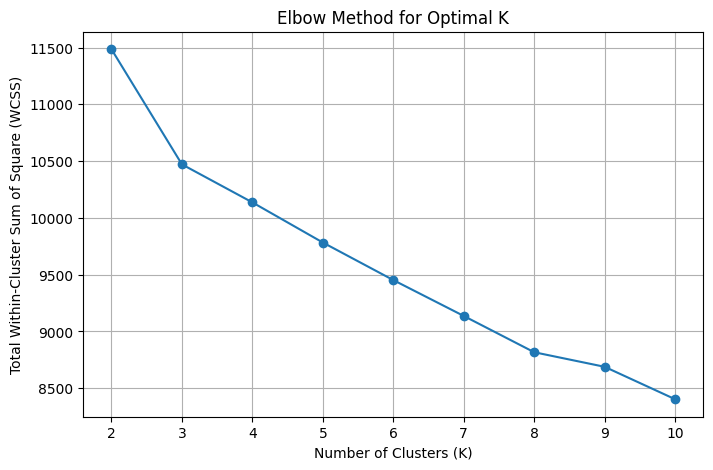

In [108]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(list(k_values), wcss, marker='o')
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Total Within-Cluster Sum of Square (WCSS)")
plt.grid(True)
plt.show()


The largest reduction in WCSS occurs between K = 2 and K = 3, after which the decrease becomes gradual. This indicates the elbow point is at K = 3.


### Silhouette


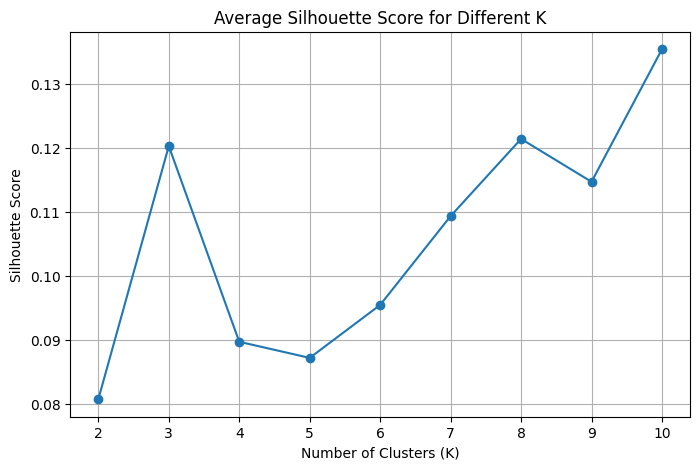

In [109]:
plt.figure(figsize=(8,5))
plt.plot(list(k_values), silhouette_scores, marker='o')
plt.title("Average Silhouette Score for Different K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()


K = 3 achieves a local peak (0.1203) among the smaller K values. All scores are relatively low, indicating weak cluster separation.


### Comparison of candidate K values
Based on the Elbow and Silhouette curves, three candidate values (K = 3, 4, 5) are compared using the Average Silhouette Width and the Total Within-Cluster Sum of Square.


In [110]:
from sklearn.cluster import KMeans
candidate_k = [3, 4, 5]


comparison_rows = []

for k in candidate_k:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_prepared)

    comparison_rows.append({
        "K": k,
        "Average Silhouette Width": silhouette_score(X_prepared, labels),
        "Total Within-Cluster Sum of Square": model.inertia_
    })

comparison_table = pd.DataFrame(comparison_rows)
comparison_table


,K,Average Silhouette Width,Total Within-Cluster Sum of Square
0,3,0.120269,10471.426520
1,4,0.089699,10136.570328
2,5,0.087181,9783.281122


**K = 3:** Highest Average Silhouette Width (0.1203) and WCSS = 10471.43. It is the elbow point and gives three balanced clusters, so it provides the best balance between separation and simplicity.

**K = 4:** Silhouette drops to 0.0897 while WCSS decreases only slightly (10136.57). The extra cluster adds overlap without improving separation.

**K = 5:** Lowest Silhouette (0.0872) and WCSS = 9783.28. Clusters are more compact but less separated and harder to interpret.


### Visualization
PCA reduces the prepared data to 2 dimensions so the clusters can be visualized for each candidate value of K.


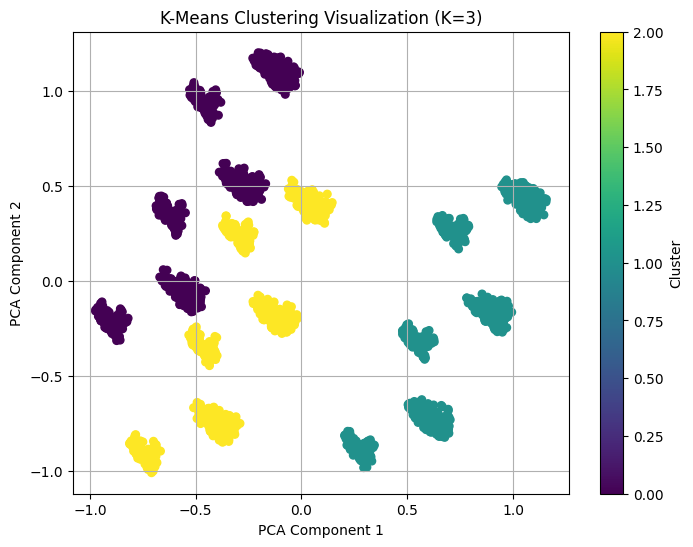

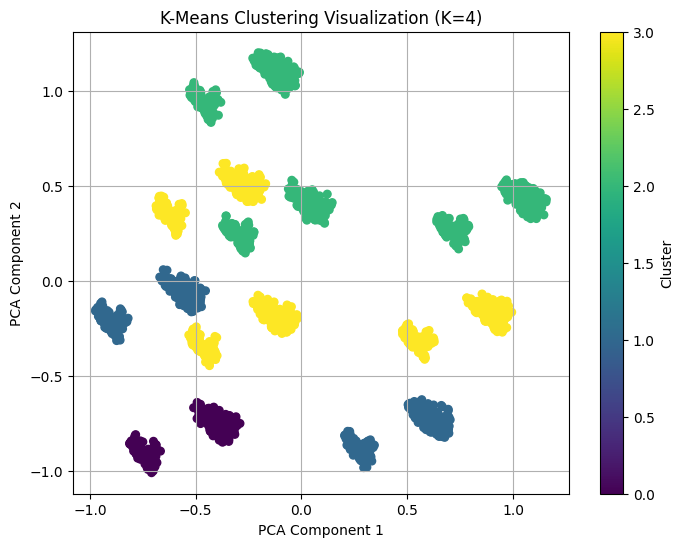

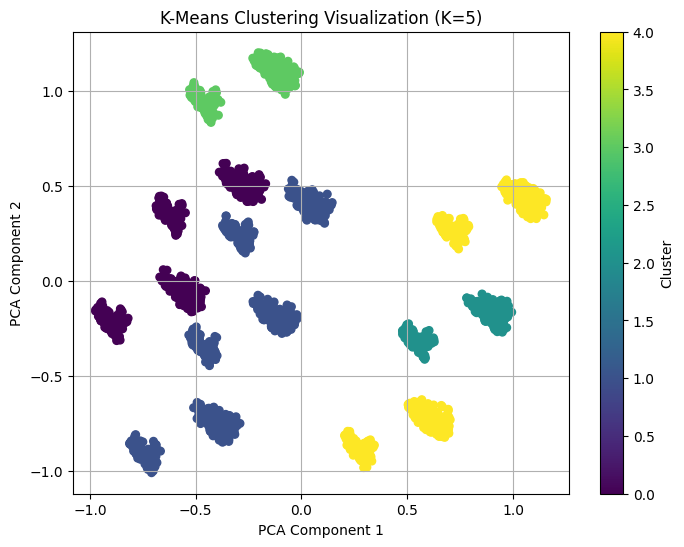

In [111]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_prepared)

for k in candidate_k:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_prepared)

    plt.figure(figsize=(8,6))
    scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap="viridis", s=30)
    plt.title(f"K-Means Clustering Visualization (K={k})")
    plt.xlabel("PCA Component 1")
    plt.ylabel("PCA Component 2")
    plt.colorbar(scatter, label="Cluster")
    plt.grid(True)
    plt.show()


The PCA visualizations show the clusters for K = 3, 4 and 5. For K = 3 the data is divided into three groups of similar size, while K = 4 and 5 create smaller groups with more overlap, making them harder to interpret.


## Clustering Evaluation
The best K is selected using the majority rule, based on the Elbow method and the Silhouette coefficient.


In [112]:
# Optimal K selected using the majority rule
best_k = 3
print("Best K:", best_k)


Best K: 3


**Final Decision (Majority Rule):**

The candidate values K = 3, 4, 5 were selected around the elbow point of the WCSS curve (the elbow itself and the two values after it).

Each evaluation method votes for the best K among the candidates:

| Method | Criterion | Best K |
|---|---|---|
| Elbow (WCSS) | Point where the decrease in WCSS slows down sharply (drop of ≈1013 from K=2 to K=3, then only ≈300–350 per step) | K = 3 |
| Silhouette Coefficient | Highest average silhouette width (0.1203 vs. 0.0897 and 0.0872) | K = 3 |

Both methods vote for K = 3, so by the majority rule **K = 3 is selected as the optimal number of clusters**.

Note: over the full range (K = 2–10), the silhouette score increases slightly for larger K (e.g., 0.135 at K = 10). However, the difference is very small, all scores are low (weak separation), and larger K values lie far beyond the elbow point and produce many small clusters that are harder to interpret. K = 3 therefore gives the best balance between separation, compactness, and interpretability.

In [113]:
best_model = KMeans(n_clusters=best_k, random_state=42, n_init=10)
best_labels = best_model.fit_predict(X_prepared)

clustered_df = df.copy()
clustered_df["Cluster"] = best_labels

clustered_df.head()


,Country,Age,Gender,Exercise Level,Diet Type,Sleep Hours,Stress Level,Mental Health Condition,Work Hours per Week,Screen Time per Day (Hours),Social Interaction Score,Happiness Score,Cluster
0,Brazil,0.652174,Male,Low,Vegetarian,0.4750,Low,Anxiety,0.025641,0.333333,0.755556,0.611111,1
1,Australia,0.282609,Male,Moderate,Vegan,0.3000,Low,PTSD,0.717949,0.533333,0.800000,0.644444,0
2,Japan,0.413043,Female,Low,Vegetarian,0.5875,High,Anxiety,0.589744,0.450000,0.955556,0.966667,1
3,Brazil,0.369565,Male,Low,Vegan,0.5875,Low,Depression,0.589744,0.033333,0.800000,0.622222,1
4,Germany,0.608696,Male,Low,Balanced,0.6000,Low,Anxiety,0.384615,0.266667,0.411111,0.377778,1


The final clustering model was applied using the selected best K. A new column called "Cluster" was added to the dataset to show the assigned cluster of each record.


In [114]:
cluster_sizes = clustered_df["Cluster"].value_counts().sort_index()
cluster_sizes


,count
Cluster,
0,998
1,1033
2,969


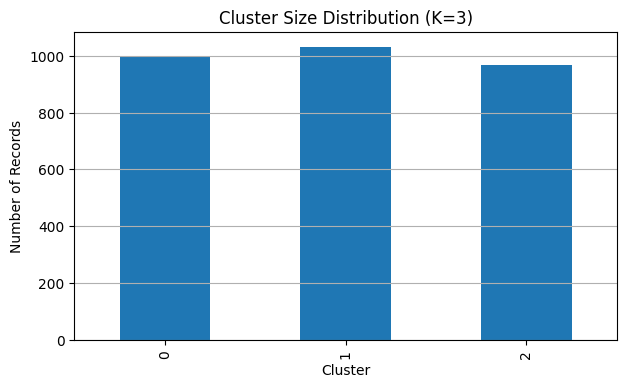

In [115]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7,4))
cluster_sizes.plot(kind="bar")
plt.title(f"Cluster Size Distribution (K={best_k})")
plt.xlabel("Cluster")
plt.ylabel("Number of Records")
plt.grid(axis="y")
plt.show()


In [116]:
cluster_vs_target = pd.crosstab(
    clustered_df["Cluster"],
    clustered_df[target_col],
    normalize="index"
) * 100

cluster_vs_target.round(2)


Stress Level,High,Low,Moderate
Cluster,,,
0,33.47,34.87,31.66
1,31.56,34.56,33.88
2,35.29,31.27,33.44


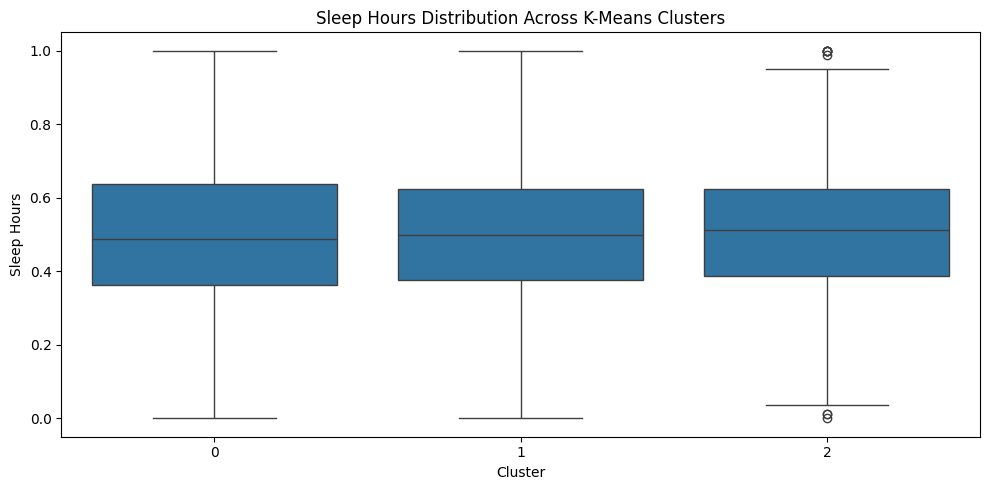

In [117]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.boxplot(data=clustered_df, x="Cluster", y="Sleep Hours")
plt.title("Sleep Hours Distribution Across K-Means Clusters")
plt.xlabel("Cluster")
plt.ylabel("Sleep Hours")
plt.tight_layout()
plt.show()

**Sleep Hours Across Clusters:** The boxplot shows that sleep-hour distributions are relatively similar across the three clusters, with considerable overlap between them. This suggests that sleep hours alone do not clearly distinguish the clusters. The result is consistent with the relatively low Silhouette Score (0.1203), which indicates weak overall cluster separation.

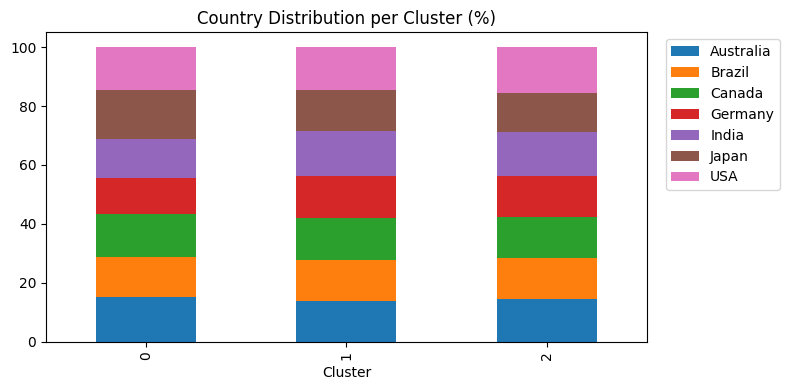

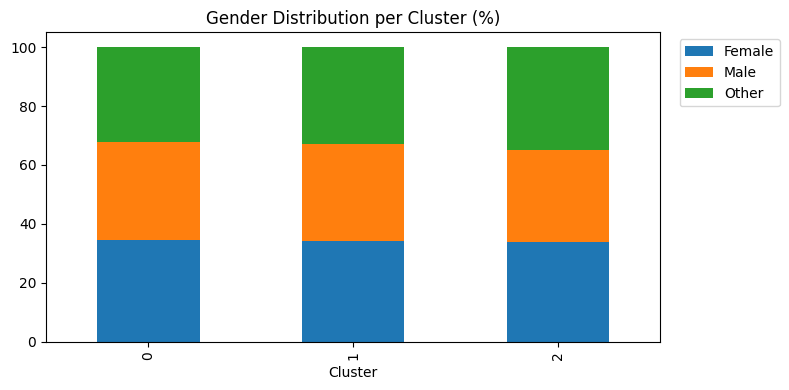

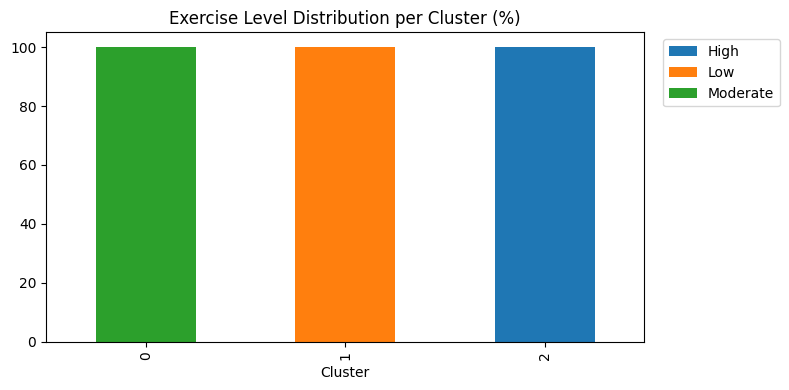

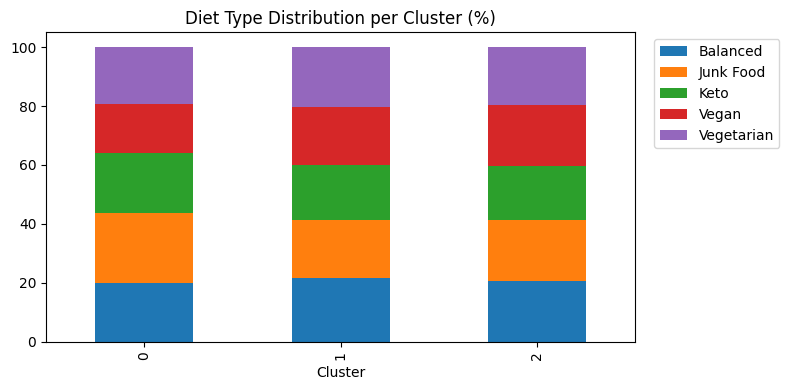

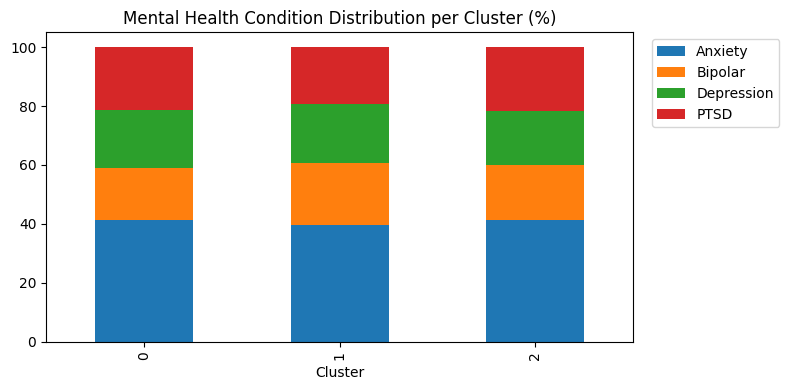

In [118]:
for col in categorical_cols:
    dist = pd.crosstab(clustered_df["Cluster"], clustered_df[col], normalize="index") * 100
    dist.plot(kind="bar", stacked=True, figsize=(8, 4))
    plt.title(f"{col} Distribution per Cluster (%)")
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


**Cluster Interpretation:** The categorical plots show that the clusters are defined almost entirely by Exercise Level:

- **Cluster 0:** individuals with Moderate exercise
- **Cluster 1:** individuals with Low exercise
- **Cluster 2:** individuals with High exercise

The other categorical attributes (Country, Gender, Diet Type and Mental Health Condition) are distributed almost equally across the clusters, and each cluster contains a roughly equal mix of Low, Moderate and High stress. This means K-Means grouped people by their exercise habits, but exercise level alone does not separate stress levels in this dataset.


## Findings and Discussion (Clustering)

K-Means clustering was applied to the preprocessed dataset after one-hot encoding the categorical attributes, producing a 28-dimensional feature space. The Elbow method (WCSS) and the Silhouette coefficient were computed for K from 2 to 10, and three candidates (K = 3, 4, 5) were compared in detail. K = 3 is the elbow point and has the highest Silhouette Score among the candidates (0.1203), so it was selected by the majority rule.

Cluster profiling showed that the three clusters correspond to the three Exercise Level groups (Low, Moderate and High), while the numeric attributes and the other categorical attributes are distributed almost equally across clusters. Although K = 3 matches the number of Stress Level classes, each cluster contains a roughly even mix of Low, Moderate and High stress. The low Silhouette Score confirms that the data does not form strongly separated natural groups.

This is consistent with the classification results, where the best Decision Tree accuracy was only 37.17%. Both techniques indicate that stress level is not strongly determined by the available lifestyle and demographic features alone.


# **7. Findings and Discussion**

This study applied two data mining techniques — Decision Tree classification and K-Means clustering — to the Mental Health and Lifestyle dataset to study Stress Level.

**Classification:** The Decision Tree was tested with two attribute selection measures (Gini index and Entropy) across three partitions (90/10, 80/20, 70/30). Both measures produced similar, modest accuracy (around 31–37%), with the best overall result from the Gini Index using the 80/20 split (37.17%). This indicates that the available lifestyle and demographic features are weak predictors of stress level on their own.
As shown in the final Decision Tree (Gini, 80/20) in Section 6, the root split is on Screen Time per Day (Hours), followed by Sleep Hours and Work Hours per Week. This indicates that daily screen time and sleep habits are the first factors the model uses to separate stress levels. However, the low accuracy shows that these splits do not separate the classes clearly.


**Clustering:** K-Means was evaluated for K from 2 to 10 using the Elbow method (WCSS) and the Silhouette coefficient, and three candidates (K = 3, 4, 5) were compared. By the majority rule, K = 3 was selected (elbow point and highest Silhouette among the candidates, 0.1203). Cluster profiling showed that the clusters are formed mainly by Exercise Level, while each cluster contains a nearly equal mix of the three stress levels.


**Comparison of the two techniques:** Both techniques suggest that the available lifestyle and demographic features provide limited separation of stress-related patterns. The best Decision Tree classification accuracy was 37.17% using the Gini Index with the 80/20 split. For K-Means, K= 3 achieved the highest Silhouette Score (0.1203) among the candidate values, but this score indicates weak cluster separation. These results suggest that neither technique identified strong patterns in the available features.

**Comparison with the selected research paper:** Our results are consistent with Liu[2], who applied K-Means to the same dataset and also selected K = 3 (silhouette = 0.272) using the Elbow and Silhouette methods. However, Liu clustered on only three behavioral variables (screen time, sleep, social media), producing clearly separated profiles, whereas our clustering used the full feature set, giving more balanced but less separated clusters. This shows that focusing on a few strongly related behaviors reveals clearer at-risk groups.


# **8. References**

[1] A. Soundankar, "Mental Health and Lifestyle Habits (2019–2024)," Kaggle, 2024. [Online]. Available: https://www.kaggle.com/datasets/atharvasoundankar/mental-health-and-lifestyle-habits-2019-2024 (accessed Nov. 2026).

[2] W. Liu, "Digital behavior and anxiety in the post-pandemic era: a five-year analysis of screen time, sleep, and behavioral risk profiles," *Front. Public Health*, vol. 14, Art. no. 1766808, Feb. 2026, doi: 10.3389/fpubh.2026.1766808.
